In [1]:
#GAN
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Use GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device selected:", device)

PyTorch version: 2.11.0+cu130
Device selected: cuda


In [2]:
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(100, 256),
            nn.ReLU(),

            nn.Linear(256, 784),
            nn.ReLU(),

            nn.Linear(784, 784),
            nn.Tanh()
        )

    def forward(self, x):
        return self.model(x).view(-1, 1, 28, 28)


generator = Generator().to(device)

print("Generator created successfully!")

Generator created successfully!


In [3]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x.view(-1, 784))


discriminator = Discriminator().to(device)

print("Discriminator created successfully!")

Discriminator created successfully!


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=64,
    shuffle=True
)

print("MNIST dataset loaded successfully!")
print("Number of training images:", len(dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 67.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.65MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.6MB/s]

MNIST dataset loaded successfully!
Number of training images: 60000


In [5]:
def train_gan(generator, discriminator, dataloader, num_epochs=5):
    criterion = nn.BCELoss()

    g_optimizer = optim.Adam(
        generator.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )

    d_optimizer = optim.Adam(
        discriminator.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )

    for epoch in range(num_epochs):
        for real_data, _ in dataloader:
            batch_size = real_data.size(0)
            real_data = real_data.to(device)

            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            # Train the Discriminator
            d_optimizer.zero_grad()

            real_output = discriminator(real_data)
            d_loss_real = criterion(real_output, real_labels)

            noise = torch.randn(batch_size, 100, device=device)
            fake_data = generator(noise)

            fake_output = discriminator(fake_data.detach())
            d_loss_fake = criterion(fake_output, fake_labels)

            d_loss = d_loss_real + d_loss_fake
            d_loss.backward()
            d_optimizer.step()

            # Train the Generator
            g_optimizer.zero_grad()

            fake_output = discriminator(fake_data)
            g_loss = criterion(fake_output, real_labels)

            g_loss.backward()
            g_optimizer.step()

        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"D Loss: {d_loss.item():.4f}, "
            f"G Loss: {g_loss.item():.4f}"
        )


train_gan(generator, discriminator, dataloader, num_epochs=5)

Epoch [1/5], D Loss: 0.9444, G Loss: 1.3541
Epoch [2/5], D Loss: 0.5012, G Loss: 2.1887
Epoch [3/5], D Loss: 0.5707, G Loss: 2.5150
Epoch [4/5], D Loss: 0.6941, G Loss: 1.3378
Epoch [5/5], D Loss: 0.7595, G Loss: 2.8796


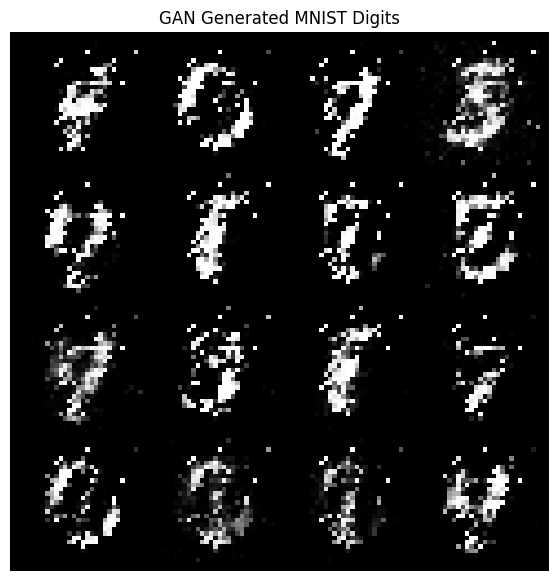

Image saved as generated_images.png


In [6]:
def generate_images(generator, num_images=16):
    generator.eval()

    with torch.no_grad():
        noise = torch.randn(num_images, 100, device=device)
        generated_images = generator(noise)

        # Convert pixel range [-1, 1] to [0, 1]
        generated_images = (generated_images + 1) / 2

        grid = torchvision.utils.make_grid(
            generated_images.cpu(),
            nrow=4,
            normalize=False,
            padding=2
        )

    # Display the grid
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.title("GAN Generated MNIST Digits")
    plt.axis("off")
    plt.show()

    # Save the generated image grid
    torchvision.utils.save_image(
        grid,
        "generated_images.png"
    )

    print("Image saved as generated_images.png")


generate_images(generator)